# Halvorsen single test trajectory

This notebook creates one `halvorsen_a_chaotic_to_periodic` test trajectory with adjustable parameter drift and evaluates it directly in memory.

Edit the parameters in the next cell, rerun the simulation cell, then run the DynaMix evaluation cells. Saving `test.npy` is optional and disabled by default.

In [9]:
from __future__ import annotations

import inspect
import json
import math
import sys
from dataclasses import asdict, replace
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d
import torch

try:
    from safetensors.torch import load_file as load_safetensors
except ImportError:
    load_safetensors = None

from generate_dynamic_regime_trajectories import (
    default_regimes,
    normalize_phi,
    simulate_regime,
    standardize_trajectories,
)

MASTER = Path(
    r"C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis"
)
DYNAMIX_REPO = MASTER / "DynaMix-python"
DYNAMIX_RUN = DYNAMIX_REPO / "results" / "full-model"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


In [10]:
# Drift experiment knobs
a_start = 1.5
a_end = 2.0
boundary = 1.75

# Drift speed is controlled by dt and total_steps: physical duration = (total_steps - 1) * dt.
# Shorter total_steps or larger a_end-a_start means faster parameter drift per sampled point.
context_steps = 500
forecast_steps = 1000
total_steps = context_steps + forecast_steps
dt = 0.01

# One trajectory by default. Increase this if you want a small batch in test.npy.
n_trajectories = 1
seed = 8
burn_in_steps = 5000
rtol = 1e-6
atol = 1e-8
max_step_multiplier = 5.0

SAVE_OUTPUT = False
OUTPUT_DIR = Path("single_halvorsen_quick_test")
TRAJECTORY_IDS = list(range(n_trajectories))

print("Physical duration:", (total_steps - 1) * dt)
print("Parameter drift per step:", (a_end - a_start) / max(total_steps - 1, 1))
print("Save output:", SAVE_OUTPUT)
if SAVE_OUTPUT:
    print("Output dir:", OUTPUT_DIR.resolve())

Physical duration: 14.99
Parameter drift per step: 0.000333555703802535
Save output: False


In [11]:
# 1. Zufälliger Anfangszustand
# 2. 5000 Schritte bei konstantem a = 1.40
# 3. Endzustand davon wird neuer Startpunkt
# 4. Aufnahme der Testtrajektorie beginnt
# 5. Während der Aufnahme driftet a linear von 1.40 nach 2.10
# 6. DynaMix bekommt die ersten 500 Punkte und forecastet die nächsten 1000


def get_halvorsen_regime():
    regimes = {regime.name: regime for regime in default_regimes()}
    base = regimes["halvorsen_a_chaotic_to_periodic"]
    return replace(base, start=a_start, end=a_end, boundary=boundary)


rng = np.random.default_rng(seed)
regime = get_halvorsen_regime()

trajectories, phi, phi_raw = simulate_regime(
    regime,
    n_steps=total_steps,
    dt=dt,
    n_trajectories=n_trajectories,
    rng=rng,
    rtol=rtol,
    atol=atol,
    max_step_multiplier=max_step_multiplier,
    burn_in_steps=burn_in_steps,
    parameter_mode="linear",
    constant_parameter="start",
)

# Match generate_dynamic_regime_trajectories.py: standardize per simulated series.
trajectories_std, mean, std = standardize_trajectories(trajectories)
test = trajectories_std.transpose(1, 0, 2).astype(np.float32)
test_phi = (
    np.repeat(phi[None, :, :], n_trajectories, axis=0)
    .transpose(1, 0, 2)
    .astype(np.float32)
)
test_phi_raw = (
    np.repeat(phi_raw[None, :, :], n_trajectories, axis=0)
    .transpose(1, 0, 2)
    .astype(np.float32)
)

metadata = {
    "description": "Single Halvorsen a chaotic-to-periodic test trajectory for DynaMix evaluation.",
    "regime": asdict(regime),
    "context_steps": context_steps,
    "forecast_steps": forecast_steps,
    "total_steps": total_steps,
    "dt": dt,
    "n_trajectories": n_trajectories,
    "seed": seed,
    "burn_in_steps": burn_in_steps,
    "shapes": {
        "test": list(test.shape),
        "test_phi": list(test_phi.shape),
        "test_phi_raw": list(test_phi_raw.shape),
    },
    "phi_convention": "phi = (a - boundary) / max(abs(start-boundary), abs(end-boundary)).",
}
if SAVE_OUTPUT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    np.save(OUTPUT_DIR / "test.npy", test)
    np.save(OUTPUT_DIR / "test_phi.npy", test_phi)
    np.save(OUTPUT_DIR / "test_phi_raw.npy", test_phi_raw)
    np.save(OUTPUT_DIR / "halvorsen_a_chaotic_to_periodic_mean.npy", mean)
    np.save(OUTPUT_DIR / "halvorsen_a_chaotic_to_periodic_std.npy", std)
    (OUTPUT_DIR / "metadata.json").write_text(
        json.dumps(metadata, indent=2), encoding="utf-8"
    )
    print("Saved", OUTPUT_DIR.resolve())
else:
    print("Generated in memory only. Set SAVE_OUTPUT = True if you want files.")

print("test.npy:", test.shape)
print("test_phi.npy:", test_phi.shape)
print(f"context slice: test[0:{context_steps}]")
print(f"target slice:  test[{context_steps}:{context_steps + forecast_steps}]")

Generated in memory only. Set SAVE_OUTPUT = True if you want files.
test.npy: (1500, 1, 3)
test_phi.npy: (1500, 1, 1)
context slice: test[0:500]
target slice:  test[500:1500]


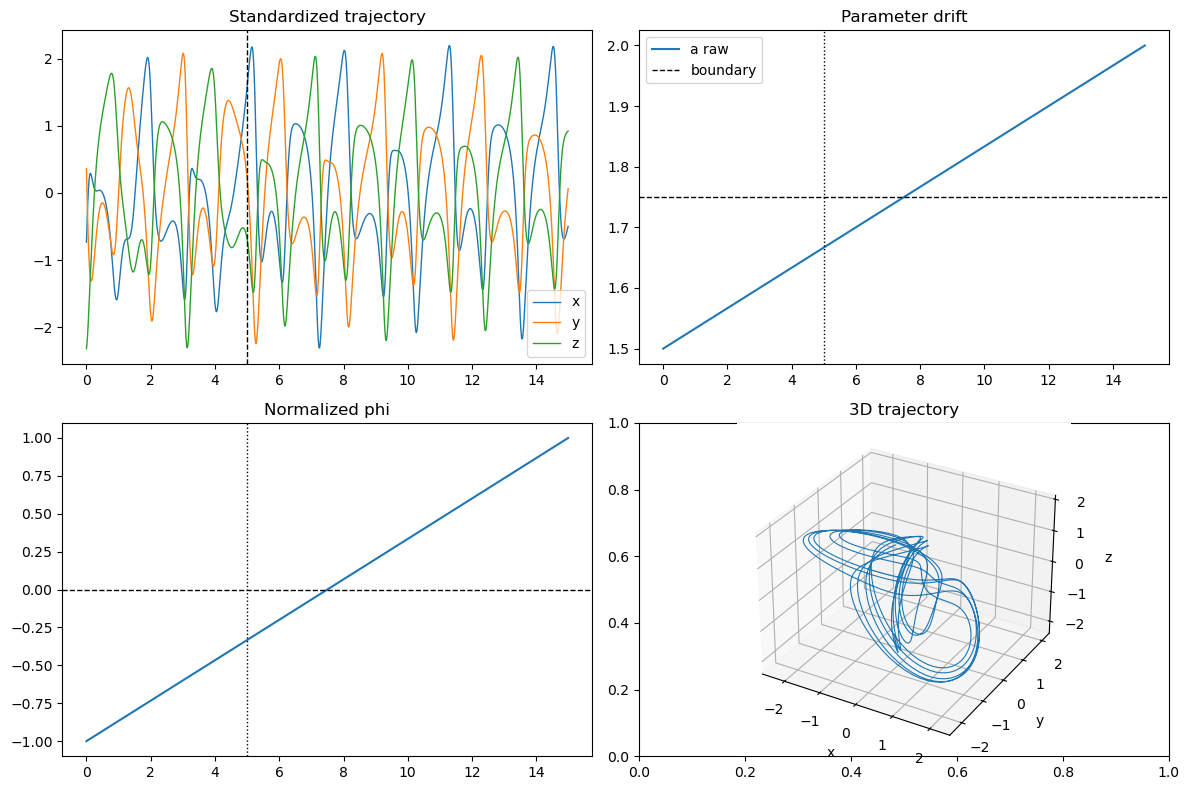

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
t = np.arange(total_steps) * dt

for dim, label in enumerate(["x", "y", "z"]):
    axes[0, 0].plot(t, test[:, 0, dim], lw=1.0, label=label)
axes[0, 0].axvline(context_steps * dt, color="black", ls="--", lw=1.0)
axes[0, 0].set_title("Standardized trajectory")
axes[0, 0].legend()

axes[0, 1].plot(t, test_phi_raw[:, 0, 0], lw=1.5, label="a raw")
axes[0, 1].axhline(boundary, color="black", ls="--", lw=1.0, label="boundary")
axes[0, 1].axvline(context_steps * dt, color="black", ls=":", lw=1.0)
axes[0, 1].set_title("Parameter drift")
axes[0, 1].legend()

axes[1, 0].plot(t, test_phi[:, 0, 0], lw=1.5)
axes[1, 0].axhline(0.0, color="black", ls="--", lw=1.0)
axes[1, 0].axvline(context_steps * dt, color="black", ls=":", lw=1.0)
axes[1, 0].set_title("Normalized phi")

ax3d = fig.add_subplot(2, 2, 4, projection="3d")
ax3d.plot(test[:, 0, 0], test[:, 0, 1], test[:, 0, 2], lw=0.8)
ax3d.set_title("3D trajectory")
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")

plt.tight_layout()

## Normal DynaMix evaluation

The cells below load `MASTER / "DynaMix-python" / "results" / "full-model"` and forecast from the first `context_steps` points using the in-memory `test` array.

In [13]:
def purge_dynamix_modules() -> None:
    for name in list(sys.modules):
        if name == "dynamix" or name.startswith("dynamix."):
            del sys.modules[name]


def import_from_repo(repo: Path):
    purge_dynamix_modules()
    src = str(repo / "src")
    sys.path = [p for p in sys.path if not p.endswith(r"DynaMix-python\src")]
    sys.path.insert(0, src)

    from dynamix.model.dynamix import DynaMix
    from dynamix.model.forecaster import DynaMixForecaster

    return DynaMix, DynaMixForecaster


def find_checkpoint(run_dir: Path, checkpoint_name: str = "final_model") -> Path:
    checkpoint_dir = run_dir / "checkpoints"
    for suffix in (".safetensors", ".pt"):
        candidate = checkpoint_dir / f"{checkpoint_name}{suffix}"
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"No {checkpoint_name}.safetensors/.pt found in {checkpoint_dir}"
    )


def load_state_dict(checkpoint_path: Path, device: str) -> dict[str, torch.Tensor]:
    if checkpoint_path.suffix == ".safetensors":
        if load_safetensors is None:
            raise ImportError("Install safetensors to load .safetensors checkpoints")
        return load_safetensors(str(checkpoint_path), device=device)
    return torch.load(checkpoint_path, map_location=device)


def infer_architecture(
    config: dict[str, Any], state: dict[str, torch.Tensor]
) -> dict[str, Any]:
    n_obs, latent_dim = map(int, state["B"].shape)
    expert_indices = {
        int(key.split(".")[1])
        for key in state
        if key.startswith("experts.") and key.split(".")[1].isdigit()
    }
    return {
        "M": latent_dim,
        "N": n_obs,
        "Experts": len(expert_indices) or int(config["experts"]),
        "P": int(config.get("pwl_units", 2)),
        "hidden_dim": int(config.get("hidden_dim", 50)),
        "expert_type": config.get("expert_type", "almost_linear_rnn"),
        "probabilistic_expert": bool(config.get("probabilistic_expert", False)),
    }


def calc_histogram(
    x: torch.Tensor, n_bins: int, min_: torch.Tensor, max_: torch.Tensor
) -> torch.Tensor:
    dim_x = x.shape[1]
    width = torch.clamp(max_ - min_, min=1e-8)
    coordinates = (n_bins * (x - min_) / width).long()
    inlier = ((coordinates > 0) & (coordinates < n_bins)).all(1)
    coordinates = coordinates[inlier]
    size_ = tuple(n_bins for _ in range(dim_x))
    indices = torch.ones(coordinates.shape[0], device=coordinates.device)
    return torch.sparse_coo_tensor(coordinates.t(), indices, size=size_).to_dense()


def normalize_to_pdf_with_laplace_smoothing(
    histogram: torch.Tensor, n_bins: int, smoothing_alpha: float = 10e-6
) -> torch.Tensor | None:
    if histogram.sum() == 0:
        return None
    dim_x = len(histogram.shape)
    return (histogram + smoothing_alpha) / (
        histogram.sum() + smoothing_alpha * n_bins**dim_x
    )


def kullback_leibler_divergence(
    p1: torch.Tensor | None, p2: torch.Tensor | None
) -> float:
    if p1 is None or p2 is None:
        return float("nan")
    return (p1 * torch.log(p1 / p2)).sum().item()


def geometrical_misalignment(
    x_gen: torch.Tensor, x_true: torch.Tensor, n_bins: int = 30
) -> float:
    min_, max_ = x_true.min(0).values, x_true.max(0).values
    hist_gen = calc_histogram(x_gen, n_bins=n_bins, min_=min_, max_=max_)
    hist_true = calc_histogram(x_true, n_bins=n_bins, min_=min_, max_=max_)
    p_gen = normalize_to_pdf_with_laplace_smoothing(hist_gen, n_bins=n_bins)
    p_true = normalize_to_pdf_with_laplace_smoothing(hist_true, n_bins=n_bins)
    return kullback_leibler_divergence(p_true, p_gen)


def compute_and_smooth_power_spectrum(x: np.ndarray, smoothing: int) -> np.ndarray:
    std = x.std()
    x_ = (x - x.mean()) / (std if std > 1e-8 else 1.0)
    ps = np.abs(np.fft.rfft(x_)) ** 2 * 2 / len(x_)
    ps_smoothed = gaussian_filter1d(ps, smoothing)
    total = ps_smoothed.sum()
    return ps_smoothed / total if total > 0 else ps_smoothed


def hellinger_distance(p: np.ndarray, q: np.ndarray) -> float:
    return float(np.sqrt(1 - np.sum(np.sqrt(p * q))))


def temporal_misalignment(
    x_gen: np.ndarray, x_true: np.ndarray, smoothing: int = 20
) -> float:
    dists = []
    for i in range(x_true.shape[1]):
        ps_true = compute_and_smooth_power_spectrum(x_true[:, i], smoothing)
        ps_gen = compute_and_smooth_power_spectrum(x_gen[:, i], smoothing)
        dists.append(hellinger_distance(ps_true, ps_gen))
    return float(np.mean(dists))


def mase_like_training(
    x_true: torch.Tensor, x_gen: torch.Tensor, steps: int = 10, naive_lag: int = 1
) -> float:
    steps = min(steps, x_true.shape[0])
    mase = torch.mean(torch.abs(x_true[:steps] - x_gen[:steps]), dim=0)
    naive_mase = torch.mean(torch.abs(x_gen[naive_lag:] - x_gen[:-naive_lag]), dim=0)
    return (mase / (naive_mase + 1e-8)).mean().item()


def dynamix_qualitative_metrics(
    pred: torch.Tensor,
    truth: torch.Tensor,
    n_bins: int = 30,
    ps_smoothing: int = 20,
    mase_steps: int = 10,
) -> dict[str, float]:
    pred_cpu = pred.detach().cpu()
    truth_cpu = truth.detach().cpu()
    dstsp_values = []
    dh_values = []
    mase_values = []
    for eval_id in range(truth_cpu.shape[1]):
        pred_i = pred_cpu[:, eval_id, :]
        truth_i = truth_cpu[:, eval_id, :]
        dstsp_values.append(geometrical_misalignment(pred_i, truth_i, n_bins=n_bins))
        dh_values.append(
            temporal_misalignment(
                pred_i.numpy(), truth_i.numpy(), smoothing=ps_smoothing
            )
        )
        mase_values.append(mase_like_training(truth_i, pred_i, steps=mase_steps))
    return {
        "dstsp": float(torch.nanmedian(torch.tensor(dstsp_values)).item()),
        "dh": float(torch.nanmedian(torch.tensor(dh_values)).item()),
        "mase": float(torch.nanmedian(torch.tensor(mase_values)).item()),
    }


def load_normal_dynamix(
    repo: Path = DYNAMIX_REPO, run_dir: Path = DYNAMIX_RUN, device: str = DEVICE
):
    DynaMix, DynaMixForecaster = import_from_repo(repo)
    config = json.loads((run_dir / "config.json").read_text())
    checkpoint_path = find_checkpoint(run_dir)
    state = load_state_dict(checkpoint_path, device)
    arch = infer_architecture(config, state)

    kwargs = {
        "M": arch["M"],
        "N": arch["N"],
        "Experts": arch["Experts"],
        "P": arch["P"],
        "hidden_dim": arch["hidden_dim"],
        "expert_type": arch["expert_type"],
        "probabilistic_expert": arch["probabilistic_expert"],
    }
    if "phi_dim" in inspect.signature(DynaMix).parameters:
        kwargs["phi_dim"] = 0

    model = DynaMix(**kwargs).to(device)
    model.load_state_dict(state)
    model.eval()
    return model, DynaMixForecaster(model), config, arch, checkpoint_path


@torch.no_grad()
def forecast_normal_dynamix(test_arr: np.ndarray = test):
    model, forecaster, config, arch, checkpoint_path = load_normal_dynamix()
    test_arr = test_arr.astype(np.float32)
    context = torch.tensor(test_arr[:context_steps, TRAJECTORY_IDS, :], device=DEVICE)
    truth = torch.tensor(
        test_arr[context_steps : context_steps + forecast_steps, TRAJECTORY_IDS, :],
        device=DEVICE,
    )
    pred = forecaster.forecast(context, forecast_steps)
    err = pred - truth
    mse = torch.mean(err**2).item()
    rmse = math.sqrt(mse)
    mae = torch.mean(torch.abs(err)).item()
    scale = torch.std(truth).item()
    nrmse = rmse / scale if scale > 0 else float("nan")
    qualitative = dynamix_qualitative_metrics(pred, truth)
    return {
        "pred": pred.detach().cpu().numpy(),
        "truth": truth.detach().cpu().numpy(),
        "context": context.detach().cpu().numpy(),
        "metrics": {
            "mse": mse,
            "rmse": rmse,
            "mae": mae,
            "nrmse": nrmse,
            **qualitative,
        },
        "arch": arch,
        "checkpoint": checkpoint_path,
    }

In [14]:
result = forecast_normal_dynamix(test)
print("Checkpoint:", result["checkpoint"])
print("Architecture:", result["arch"])
print("Metrics:", result["metrics"])

Checkpoint: C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis\DynaMix-python\results\full-model\checkpoints\final_model.safetensors
Architecture: {'M': 30, 'N': 3, 'Experts': 10, 'P': 2, 'hidden_dim': 50, 'expert_type': 'almost_linear_rnn', 'probabilistic_expert': False}
Metrics: {'mse': 0.9059207439422607, 'rmse': 0.9517986887689333, 'mae': 0.7445971965789795, 'nrmse': 0.937789874767009, 'dstsp': 11.5195894241333, 'dh': 0.010218162089586258, 'mase': 1.318254828453064}


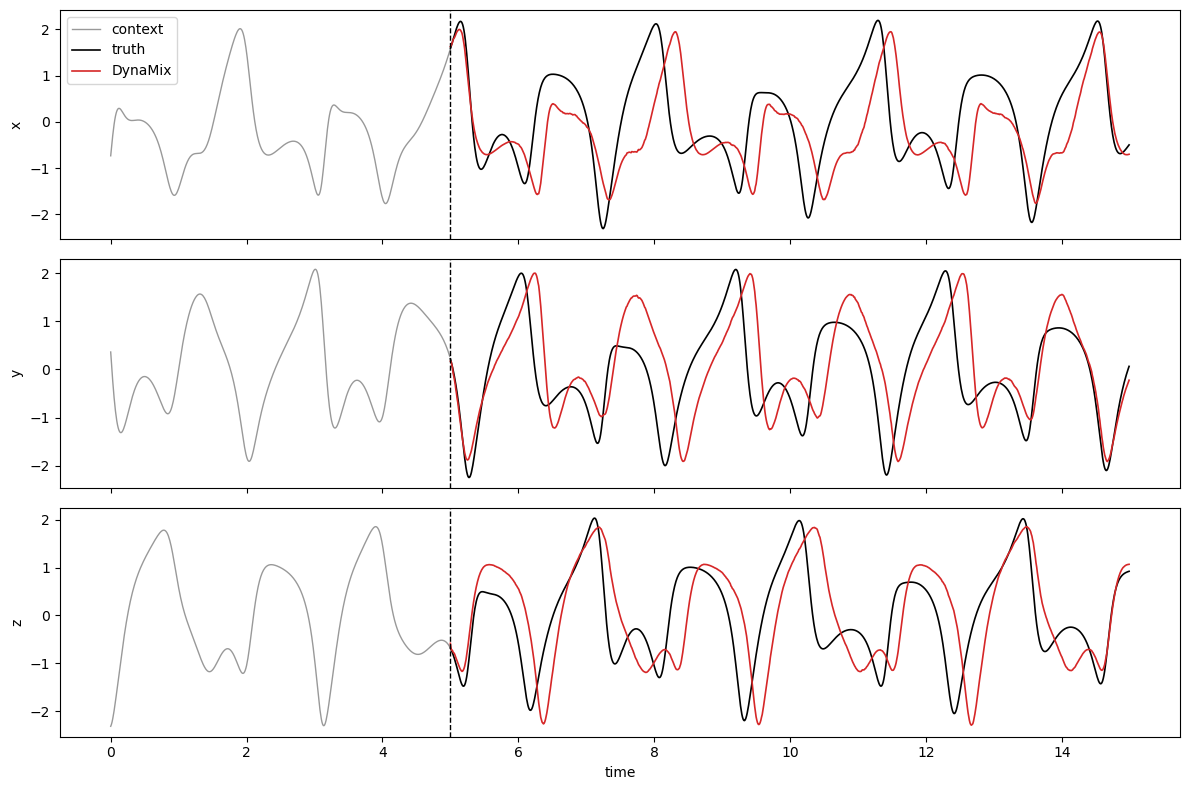

In [15]:
traj_id = 0
pred = result["pred"][:, traj_id, :]
truth = result["truth"][:, traj_id, :]
context = result["context"][:, traj_id, :]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
target_t = np.arange(context_steps, context_steps + forecast_steps) * dt
context_t = np.arange(context_steps) * dt

for dim, ax in enumerate(axes):
    ax.plot(
        context_t,
        context[:, dim],
        color="0.6",
        lw=1.0,
        label="context" if dim == 0 else None,
    )
    ax.plot(
        target_t,
        truth[:, dim],
        color="black",
        lw=1.2,
        label="truth" if dim == 0 else None,
    )
    ax.plot(
        target_t,
        pred[:, dim],
        color="#d62728",
        lw=1.2,
        label="DynaMix" if dim == 0 else None,
    )
    ax.axvline(context_steps * dt, color="black", ls="--", lw=1.0)
    ax.set_ylabel(["x", "y", "z"][dim])
axes[0].legend()
axes[-1].set_xlabel("time")
plt.tight_layout()

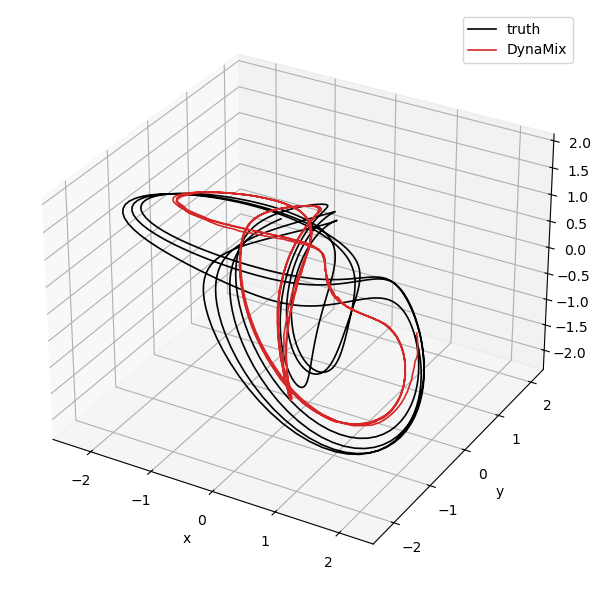

In [16]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(truth[:, 0], truth[:, 1], truth[:, 2], color="black", lw=1.2, label="truth")
ax.plot(pred[:, 0], pred[:, 1], pred[:, 2], color="#d62728", lw=1.2, label="DynaMix")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.legend()
plt.tight_layout()